# Laboratorium 04 — MLP i SimpleCNN na CIFAR-10

## 1. Wspólna konfiguracja

Oba modele trenujemy przez 10 epok, z Adamem, learning rate 0,001 i paczką 128. Ziarno wynosi 42, augmentacja jest wyłączona.

In [2]:
import copy, math, time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

CFG = {
    "epochs": 10,        # budżet epok, ten sam dla obu modeli
    "lr": 1e-3,          # learning rate (Adam)
    "batch_size": 128,
    "n_val": 5000,       # rozmiar zbioru walidacyjnego wydzielonego z treningu
    "augment": False,    # augmentacja tylko na zbiorze treningowym (rozdział 7)
    "seed": 42,
}

torch.manual_seed(CFG["seed"])
if not torch.cuda.is_available():
    raise RuntimeError("Włącz GPU w ustawieniach Google Colab.")
device = "cuda"
gpu_name = torch.cuda.get_device_name(0)
print(f"GPU: {gpu_name} | PyTorch: {torch.__version__} | torchvision: {torchvision.__version__}")
print(CFG)

GPU: Tesla T4 | PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
{'epochs': 10, 'lr': 0.001, 'batch_size': 128, 'n_val': 5000, 'augment': False, 'seed': 42}


## 2. Dane: CIFAR-10 z podziałem trening / walidacja / test

CIFAR-10 to 60 000 kolorowych obrazów 32×32 w 10 klasach (3 kanały wejścia).

- **Trening** (45 000): na nim model uczy się wag.
- **Walidacja** (5 000, wydzielona z treningu): na niej wybieramy najlepszą epokę.
- **Test** (10 000): używamy go **jeden raz**, na końcu, do oceny wybranego modelu.

Zbiór treningowy jest wczytany dwukrotnie: z augmentacją (do uczenia) i bez augmentacji (do walidacji). Podział indeksów jest losowany ze stałym ziarnem, więc jest taki sam dla obu modeli (rozdział 9.2).

Pierwsze pobranie zbioru (ok. 170 MB) może trwać kilka minut.

In [8]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_full_aug  = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_train)
train_full_eval = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_eval)

classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]
train_ds = Subset(train_full_aug, train_idx)
val_ds   = Subset(train_full_eval, val_idx)

def make_train_loader():
    return DataLoader(
        train_ds, batch_size=CFG["batch_size"], shuffle=True, num_workers=2,
        generator=torch.Generator().manual_seed(CFG["seed"]),
    )

train_dl = make_train_loader()
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)

print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: 10000 (ocena końcowa)")
assert (len(train_ds), len(val_ds)) == (45000, 5000)
assert len(set(train_idx + val_idx)) == 50000

100%|██████████| 170M/170M [16:22<00:00, 174kB/s]


Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000 (ocena końcowa)


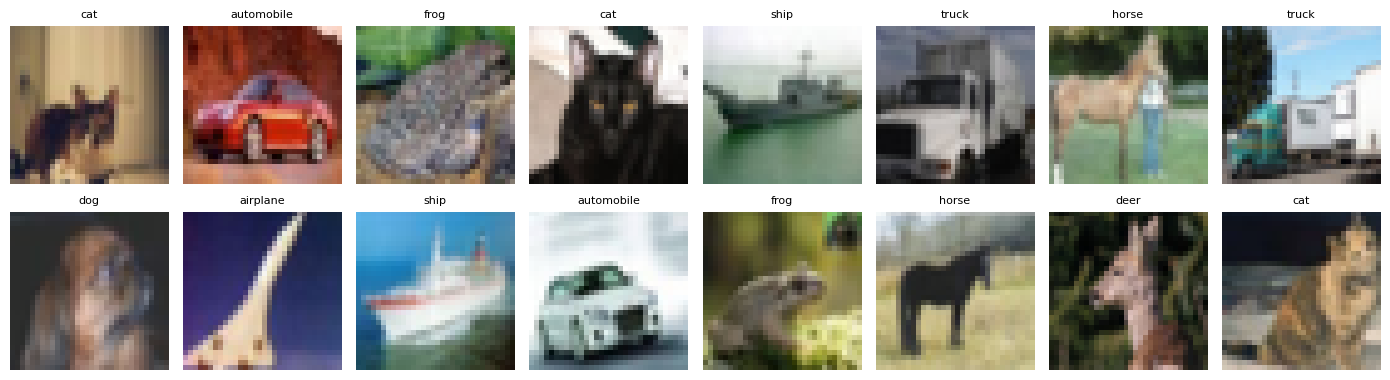

In [9]:
# Podgląd próbek; normalizację odwracamy, aby obraz miał naturalne kolory
mean_t = torch.tensor(mean).view(3, 1, 1); std_t = torch.tensor(std).view(3, 1, 1)
def denorm(img): return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Modele: MLP i SimpleCNN

**MLP** spłaszcza obraz do wektora 3072 (= 3·32·32). **SimpleCNN** ma część splotową `features` (dwa bloki: splot–BatchNorm–ReLU ×2, MaxPool) i głowicę `classifier` (warstwy gęste). Opis warstw: rozdział 6.2.

Parametry `c1`, `c2` to liczby filtrów w blokach (zakres dodatkowy zadania). Wymiar wejścia głowicy (`c2·8·8`) jest wyliczany automatycznie.

In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),                                   # H, W zmniejszone o połowę
    )

class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, c1), block(c1, c2))  # 32x32 -> 8x8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(c2*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),        # surowe logity, bez Softmax
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print(f"MLP:                   {count_params(mlp_tmp):>10,}")
print(f"CNN część splotowa:    {count_params(cnn_tmp.features):>10,}")
print(f"CNN głowica:           {count_params(cnn_tmp.classifier):>10,}")
print(f"CNN razem:             {count_params(cnn_tmp):>10,}")

MLP:                    1,707,274
CNN część splotowa:        65,952
CNN głowica:            1,051,402
CNN razem:              1,117,354


## 4. Testy kontrolne przed treningiem

Trzy szybkie testy z rozdziału 8.3. Jeżeli któryś test nie daje oczekiwanego wyniku, proszę szukać błędu w kodzie, zanim uruchomią Państwo pełny trening.

1. **Kształty:** wyjście modelu ma kształt `(N, 10)`.
2. **Strata na starcie:** ok. `ln(10) ≈ 2,30`.
3. **Przeuczenie jednej paczki:** strata spada blisko zera w ok. 100 krokach.

In [10]:
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(make_train_loader()))
xb, yb = xb.to(device), yb.to(device)
x32, y32 = xb[:32], yb[:32]

for name, build in [("MLP", MLP), ("SimpleCNN", SimpleCNN)]:
    torch.manual_seed(CFG["seed"])
    model = build().to(device).eval()
    with torch.no_grad():
        logits = model(xb)
        assert logits.shape == (len(yb), 10)
        initial_loss = crit(logits, yb).item()
    print(f"{name} | logity {tuple(logits.shape)} | strata początkowa {initial_loss:.3f} (ln(10) ≈ 2,30)")
    assert abs(initial_loss - math.log(10)) < 0.25

    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    for step in range(1, 101):
        opt.zero_grad()
        loss = crit(model(x32), y32)
        loss.backward()
        opt.step()
        if step % 25 == 0:
            print(f"  krok {step:3d} | strata {loss.item():.4f}")
    model.eval()
    with torch.no_grad():
        logits = model(x32)
        final_loss = crit(logits, y32).item()
        accuracy = (logits.argmax(1) == y32).float().mean().item()
    print(f"  po 100 krokach | strata {final_loss:.4f} | accuracy {accuracy:.0%}")
    assert final_loss < 0.2 and accuracy >= 0.95

MLP | logity (128, 10) | strata początkowa 2.303 (ln(10) ≈ 2,30)
  krok  25 | strata 0.0000
  krok  50 | strata 0.0000
  krok  75 | strata 0.0000
  krok 100 | strata 0.0000
  po 100 krokach | strata 0.0000 | accuracy 100%
SimpleCNN | logity (128, 10) | strata początkowa 2.305 (ln(10) ≈ 2,30)
  krok  25 | strata 0.0103
  krok  50 | strata 0.0002
  krok  75 | strata 0.0001
  krok 100 | strata 0.0006
  po 100 krokach | strata 0.0000 | accuracy 100%


## 5. Funkcje treningu i ewaluacji

- `train_one_epoch` — jedna epoka uczenia; zwraca średnią stratę treningową.
- `evaluate` — strata i accuracy na podanym zbiorze, w trybie `model.eval()` i bez gradientów.
- `fit` — pełny trening. Po każdej epoce liczy stratę i accuracy na treningu i walidacji. Zapamiętuje wagi z epoki o **najwyższej accuracy walidacyjnej**. Zbioru testowego `fit` nie używa.

Czas uczenia (`train_time`) obejmuje tylko pętle treningowe. Czas ewaluacji jest mierzony osobno. Przed odczytem czasu wywołujemy `torch.cuda.synchronize()`, ponieważ obliczenia GPU są asynchroniczne (rozdział 9.3).

Accuracy treningowa jest liczona osobnym przejściem przez zbiór treningowy w trybie `eval` (bez dropoutu). Dzięki temu przerwa train–walidacja jest mierzona tak samo dla obu zbiorów.

In [11]:
def sync():
    if device == "cuda": torch.cuda.synchronize()

def train_one_epoch(model, dl, opt, crit):
    model.train(); s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        s += loss.item() * yb.size(0); n += yb.size(0)
    return s / n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval(); s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
    return s / n, c / n

# Ewaluacja na treningu: te same obrazy treningowe, ale bez augmentacji
train_eval_dl = DataLoader(Subset(train_full_eval, train_idx), batch_size=256,
                           shuffle=False, num_workers=2)

def fit(build_model, cfg=CFG):
    torch.manual_seed(cfg["seed"])
    train_dl = make_train_loader()
    model = build_model().to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1.0, "epoch": 0, "state": None}
    train_time = eval_time = 0.0
    for epoch in range(1, cfg["epochs"] + 1):
        sync(); t0 = time.perf_counter()
        train_one_epoch(model, train_dl, opt, crit)
        sync(); t1 = time.perf_counter()
        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync(); t2 = time.perf_counter()
        train_time += t1 - t0; eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]): hist[k].append(v)
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"  epoka {epoch:2d} | strata tr {tr_loss:.3f} wal {va_loss:.3f}"
              f" | acc tr {tr_acc*100:5.2f}% wal {va_acc*100:5.2f}%")
    model.load_state_dict(best["state"])      # przywracamy wagi z najlepszej epoki walidacyjnej
    return {"model": model, "hist": hist, "best": best,
            "train_time": train_time, "eval_time": eval_time}

## 6. Trening: MLP i SimpleCNN

Oba modele uczymy z tą samą konfiguracją `CFG`. Na GPU w Colab każdy trening trwa zwykle kilka minut.

Uruchomienie tej komórki ponownie tworzy **nowe** modele od początku.

In [7]:
print("== MLP ==")
res_mlp = fit(MLP)
print("\n== SimpleCNN ==")
res_cnn = fit(SimpleCNN)
results = {"MLP": res_mlp, "SimpleCNN": res_cnn}

== MLP ==
  epoka  1 | strata tr 1.443 wal 1.497 | acc tr 48.95% wal 47.30%
  epoka  2 | strata tr 1.316 wal 1.422 | acc tr 53.64% wal 50.18%
  epoka  3 | strata tr 1.223 wal 1.422 | acc tr 56.68% wal 50.34%
  epoka  4 | strata tr 1.127 wal 1.377 | acc tr 60.89% wal 52.72%
  epoka  5 | strata tr 1.042 wal 1.392 | acc tr 63.14% wal 51.50%
  epoka  6 | strata tr 0.977 wal 1.402 | acc tr 65.51% wal 52.44%
  epoka  7 | strata tr 0.897 wal 1.439 | acc tr 68.15% wal 51.70%
  epoka  8 | strata tr 0.842 wal 1.460 | acc tr 70.32% wal 52.50%
  epoka  9 | strata tr 0.766 wal 1.485 | acc tr 72.92% wal 53.24%
  epoka 10 | strata tr 0.700 wal 1.505 | acc tr 75.37% wal 53.40%

== SimpleCNN ==
  epoka  1 | strata tr 1.045 wal 1.062 | acc tr 61.80% wal 61.46%
  epoka  2 | strata tr 0.822 wal 0.852 | acc tr 71.07% wal 69.90%
  epoka  3 | strata tr 0.768 wal 0.830 | acc tr 73.31% wal 71.32%
  epoka  4 | strata tr 0.629 wal 0.728 | acc tr 78.01% wal 75.04%
  epoka  5 | strata tr 0.557 wal 0.682 | acc tr 8

## 7. Końcowa ocena na zbiorze testowym

Każdy model oceniamy **jeden raz**, z wagami z epoki o najwyższej accuracy walidacyjnej. Wyniku testowego nie używamy do wyboru epoki ani konfiguracji.

Przy remisie wybieramy wcześniejszą epokę. Ponowne wyświetlenie tabeli wykorzystuje zapisany wynik testowy bieżącego przebiegu.

In [8]:
from IPython.display import Markdown, display

test_ds = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf_eval)
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)
assert len(test_ds) == 10000

print(f"GPU: {gpu_name} | Czas uczenia bez ewaluacji i testu.")
table = [
    "| Model | Parametry razem | Część splotowa | Głowica CNN | Epoka | Acc. trening | Acc. walidacja | Acc. test | Przerwa [p.p.] | Uczenie [s] | Ewaluacja [s] |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for name, r in results.items():
    model = r["model"]
    if "test_acc" not in r:
        _, r["test_acc"] = evaluate(model, test_dl, crit)
    epoch = r["best"]["epoch"]
    tr = r["hist"]["train_acc"][epoch - 1]
    va = r["best"]["val_acc"]
    features = f"{count_params(model.features):,}" if name == "SimpleCNN" else "—"
    head = f"{count_params(model.classifier):,}" if name == "SimpleCNN" else "—"
    table.append(
        f"| {name} | {count_params(model):,} | {features} | {head} | {epoch} "
        f"| {tr:.2%} | {va:.2%} | {r['test_acc']:.2%} | {100*(tr-va):+.2f} "
        f"| {r['train_time']:.1f} | {r['eval_time']:.1f} |"
    )
display(Markdown("\n".join(table)))

GPU: Tesla T4 | Czas uczenia bez ewaluacji i testu.


| Model | Parametry razem | Część splotowa | Głowica CNN | Epoka | Acc. trening | Acc. walidacja | Acc. test | Przerwa [p.p.] | Uczenie [s] | Ewaluacja [s] |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| MLP | 1,707,274 | — | — | 10 | 75.37% | 53.40% | 53.12% | +21.97 | 98.2 | 105.9 |
| SimpleCNN | 1,117,354 | 65,952 | 1,051,402 | 10 | 88.20% | 79.12% | 78.66% | +9.08 | 110.2 | 108.3 |

## 8. Krzywe uczenia

Lewy wykres: strata, prawy: accuracy. Linie ciągłe to trening, przerywane to walidacja. Pionowa kropkowana linia oznacza epokę wybraną na walidacji.

Interpretacja krzywych: tabela w rozdziale 8.2 wstępu. Duża i rosnąca przerwa między linią ciągłą a przerywaną oznacza przeuczenie.

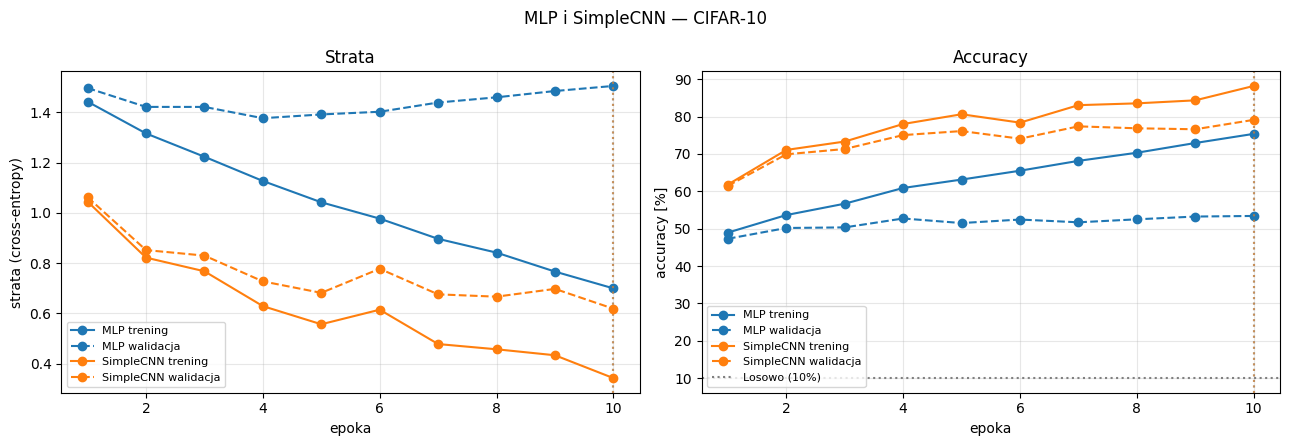

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in [("MLP", res_mlp, "tab:blue"), ("SimpleCNN", res_cnn, "tab:orange")]:
    h = r["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "-o", color=color, label=f"{name} trening")
    ax2.plot(ep, [a*100 for a in h["val_acc"]], "--o", color=color, label=f"{name} walidacja")
    for ax in (ax1, ax2): ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)
ax1.set(xlabel="epoka", ylabel="strata (cross-entropy)", title="Strata")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
ax2.axhline(10, color="gray", ls=":", label="Losowo (10%)")
for ax in (ax1, ax2): ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("MLP i SimpleCNN — CIFAR-10"); plt.tight_layout(); plt.show()

## 9. Mapy cech pierwszej i głębszej warstwy splotowej

Jeden obraz walidacyjny przechodzi przez:

- pierwszą warstwę splotową `features[0][0]` (filtry 3×3 na obrazie RGB, mapy 32×32),
- pierwszą warstwę splotową drugiego bloku `features[1][0]` (wejście: wyjście całego pierwszego bloku, mapy 16×16).

Pokazujemy ReLU wyjścia samego splotu, bez BatchNorm. To podgląd reakcji filtrów, a nie etykiety klas (rozdział 6.5).

mapy warstwy 1: (32, 32, 32) | mapy warstwy głębszej: (64, 16, 16)


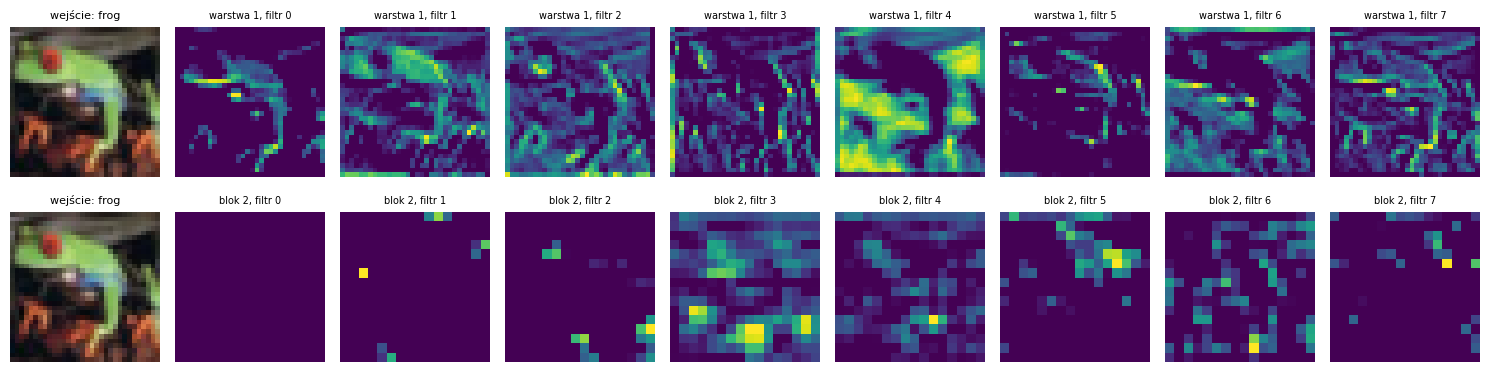

In [10]:
cnn = res_cnn["model"].eval()
img, label = val_ds[0]
x = img.unsqueeze(0).to(device)                       # [3,32,32] -> [1,3,32,32]
with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()          # [32, 32, 32]
    after_block1 = cnn.features[0](x)                           # [1, 32, 16, 16]
    maps2 = torch.relu(cnn.features[1][0](after_block1))[0].cpu()  # [64, 16, 16]
print("mapy warstwy 1:", tuple(maps1.shape), "| mapy warstwy głębszej:", tuple(maps2.shape))

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for row, (maps, title) in enumerate([(maps1, "warstwa 1"), (maps2, "blok 2")]):
    axes[row, 0].imshow(denorm(img)); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"wejście: {classes[label]}", fontsize=8)
    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis"); ax.axis("off")
        ax.set_title(f"{title}, filtr {i}", fontsize=7)
plt.tight_layout(); plt.show()

## 10. Wnioski z pomiarów

Komentarz poniżej powstaje na podstawie metryk z bieżącego przebiegu.

In [11]:
cnn = res_cnn["model"]
p_mlp = count_params(res_mlp["model"])
p_cnn = count_params(cnn)
head_share = count_params(cnn.classifier) / p_cnn
dv = 100 * (res_cnn["best"]["val_acc"] - res_mlp["best"]["val_acc"])
dt = 100 * (res_cnn["test_acc"] - res_mlp["test_acc"])
notes = [
    f"- **Porównanie accuracy.** Różnica SimpleCNN minus MLP wynosi {dv:+.2f} p.p. "
    f"na walidacji i {dt:+.2f} p.p. na teście. Względem losowego poziomu 10% "
    f"różnica testowa wynosi {100 * res_mlp['test_acc'] - 10:+.2f} p.p. dla MLP "
    f"i {100 * res_cnn['test_acc'] - 10:+.2f} p.p. dla SimpleCNN.",
    f"- **Parametry i splot.** MLP ma {p_mlp:,} parametrów, a SimpleCNN ma {p_cnn:,}. "
    f"Głowica skupia {head_share:.1%} parametrów CNN. Filtr 3×3 analizuje lokalne sąsiedztwo "
    "i używa tych samych wag w kolejnych pozycjach obrazu. Pierwsza warstwa MLP przypisuje "
    "każdemu neuronowi osobne wagi dla wszystkich 3072 składowych obrazu.",
]
if dv < 1 or dt < 1:
    notes.append(
        "- **Mała lub ujemna przewaga CNN.** Obie architektury mogły uczyć się w różnym tempie "
        "przy wspólnym budżecie 10 epok i identycznym learning rate."
    )
else:
    notes.append(
        "- **Przewaga CNN.** Wyższa accuracy walidacyjna i testowa przy mniejszej liczbie parametrów "
        "jest zgodna z tym, że lokalne i współdzielone filtry sprzyjają klasyfikacji obrazów. "
        "Porównanie obejmuje też różnice w poolingu, BatchNorm i dropoucie."
    )

for name, r in results.items():
    h = r["hist"]
    i = r["best"]["epoch"] - 1
    gaps = [100 * (a - b) for a, b in zip(h["train_acc"], h["val_acc"])]
    j = min(range(len(h["val_loss"])), key=h["val_loss"].__getitem__)
    d_train = h["train_loss"][-1] - h["train_loss"][j]
    d_val = h["val_loss"][-1] - h["val_loss"][j]
    if d_train < 0 and d_val >= 0.02:
        comment = "Spadek straty treningowej przy wzroście walidacyjnej wskazuje na przeuczenie pod koniec przebiegu."
    elif gaps[-1] - gaps[0] >= 2:
        comment = "Rosnąca przerwa accuracy wskazuje na nasilające się różnice między treningiem a walidacją."
    else:
        comment = "Przebieg tych metryk daje słabsze przesłanki narastającego przeuczenia."
    notes.append(
        f"- **{name} i przeuczenie.** Przerwa accuracy wynosi {gaps[0]:+.2f} p.p. w pierwszej epoce, "
        f"{gaps[i]:+.2f} p.p. w wybranej ({i + 1}) i {gaps[-1]:+.2f} p.p. w ostatniej. "
        f"Od minimum straty walidacyjnej (epoka {j + 1}) strata treningowa zmieniła się "
        f"o {d_train:+.3f}, a walidacyjna o {d_val:+.3f}. {comment}"
    )
display(Markdown("\n".join(notes)))

- **Porównanie accuracy.** Różnica SimpleCNN minus MLP wynosi +25.72 p.p. na walidacji i +25.54 p.p. na teście. Względem losowego poziomu 10% różnica testowa wynosi +43.12 p.p. dla MLP i +68.66 p.p. dla SimpleCNN.
- **Parametry i splot.** MLP ma 1,707,274 parametrów, a SimpleCNN ma 1,117,354. Głowica skupia 94.1% parametrów CNN. Filtr 3×3 analizuje lokalne sąsiedztwo i używa tych samych wag w kolejnych pozycjach obrazu. Pierwsza warstwa MLP przypisuje każdemu neuronowi osobne wagi dla wszystkich 3072 składowych obrazu.
- **Przewaga CNN.** Wyższa accuracy walidacyjna i testowa przy mniejszej liczbie parametrów jest zgodna z tym, że lokalne i współdzielone filtry sprzyjają klasyfikacji obrazów. Porównanie obejmuje też różnice w poolingu, BatchNorm i dropoucie.
- **MLP i przeuczenie.** Przerwa accuracy wynosi +1.65 p.p. w pierwszej epoce, +21.97 p.p. w wybranej (10) i +21.97 p.p. w ostatniej. Od minimum straty walidacyjnej (epoka 4) strata treningowa zmieniła się o -0.427, a walidacyjna o +0.128. Spadek straty treningowej przy wzroście walidacyjnej wskazuje na przeuczenie pod koniec przebiegu.
- **SimpleCNN i przeuczenie.** Przerwa accuracy wynosi +0.34 p.p. w pierwszej epoce, +9.08 p.p. w wybranej (10) i +9.08 p.p. w ostatniej. Od minimum straty walidacyjnej (epoka 10) strata treningowa zmieniła się o +0.000, a walidacyjna o +0.000. Rosnąca przerwa accuracy wskazuje na nasilające się różnice między treningiem a walidacją.